# Burndown

Cada commit conta como 1 tarefa concluída. Rode na raiz do repositório ou em `docs/`.

In [1]:
import subprocess
from collections import Counter
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

saida = subprocess.check_output(
    ["git", "log", "--reverse", "--format=%an|%ad|%s", "--date=short"], text=True
)
linhas = [l.split("|", 2) for l in saida.splitlines()]
commits = pd.DataFrame(linhas, columns=["autor", "dia", "msg"])
commits["dia"] = pd.to_datetime(commits["dia"])
commits["autor"].value_counts()

autor
mikael                     9
jcesar-fx                  5
Vinícius Martins Borges    5
Name: count, dtype: int64

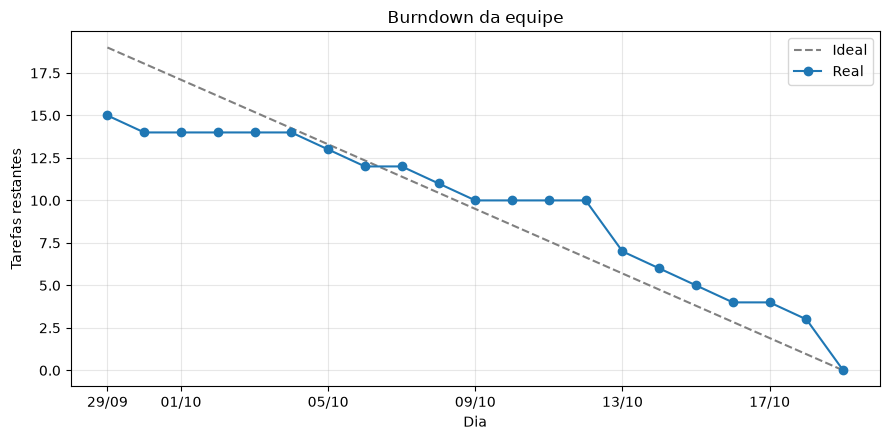

In [2]:
dias = pd.date_range(commits["dia"].min(), commits["dia"].max())
feitas = commits.groupby("dia").size().reindex(dias, fill_value=0).cumsum()
total = len(commits)
restantes = total - feitas
ideal = pd.Series([total * (1 - i / (len(dias) - 1)) for i in range(len(dias))], index=dias)

plt.figure(figsize=(9, 4.5))
plt.plot(ideal, "--", color="gray", label="Ideal")
plt.plot(restantes, marker="o", label="Real")
plt.title("Burndown da equipe")
plt.xlabel("Dia")
plt.ylabel("Tarefas restantes")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("burndown.png", dpi=150)
plt.show()

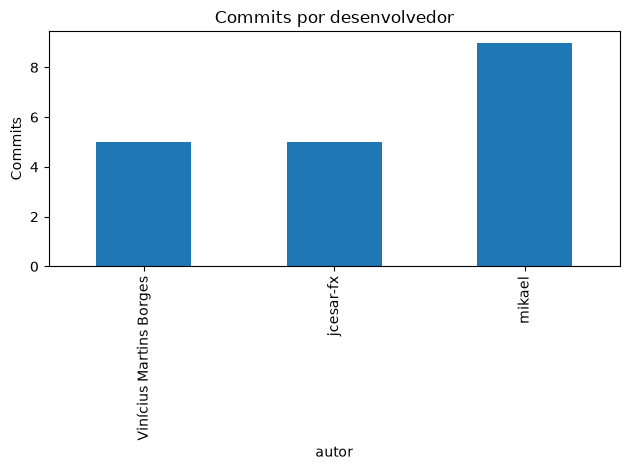

In [3]:
commits.groupby("autor")["msg"].count().plot.bar(title="Commits por desenvolvedor")
plt.ylabel("Commits")
plt.tight_layout()
plt.show()